# Tarefa 3 — Primeira árvore de decisão (ICMPMASTER)

**Objetivo:** treinar a **árvore de decisão oficial** (só métricas relativas ao baseline do fluxo), avaliá-la na **validação**, ler as regras em português e treinar uma **árvore de contraste** para mostrar que o atalho da distância (RTT absoluto / mediana do caminho) não é o modelo do projeto.

> Este notebook **não refaz** a ficha de baseline nem a tabela de classes da Tarefa 2. Ele apenas **lê** `dataset_rotulado_B.csv` e `baseline_por_fluxo.csv`.
>
> O teste fica **fechado** até a Tarefa 5. Não há troca de algoritmo (floresta, boosting, redes), limiar fino nem model card nesta etapa.

## Entrega mínima

- Uma árvore CART com critério, `max_depth` e `min_samples_leaf` declarados (escolhidos **só pela validação**);
- Regras da árvore copiadas da própria árvore e lidas em português;
- Matriz 3×3, precisão/recall/F1 por classe e F1 macro na validação;
- Dois erros concretos (ou a declaração de que o caso não apareceu);
- Árvore de contraste, o que ela usou na raiz e a declaração de que fica fora da entrega final.

## Pipeline da Tarefa 3

```
dataset_rotulado_B.csv  ──┐
baseline_por_fluxo.csv  ──┴─► 1. carregar + partição (treino/validação/teste da Tarefa 2)
                              2. escolher hiperparâmetros (grade, SÓ validação)
                              3. fit da árvore oficial (SÓ treino)
                              4. regras em português + importância das colunas
                              5. leitura do erro (matriz 3×3, F1, erros concretos)
                              6. árvore de contraste (rota/RTT absoluto) → descartada
                              7. registro final
```

## 1. Identificação da equipe

- **Equipe:** ICMPMASTER
- **Integrantes:**
    - Eduardo Quintino Filho
    - Felipe Veiga da Silva
    - Henrique de Aguiar Fernandes
    - Niccolas Lupetti dos Santos
    - Tharik Lima da Silva
- **Scrum Master da tarefa:** Henrique de Aguiar Fernandes
- **Período da tarefa:** 28/09/2026 a 04/10/2026
- **Repositório GitHub:** https://github.com/sgntgifc0c/icmpmaster

## 2. Bibliotecas

In [2]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 3. Configuração

Todos os parâmetros ficam nesta célula (nomes de arquivos, colunas, grade e semente), como na `config/` da coleta.

- `DATASET_B` e `BASELINE`: saídas da Tarefa 2, usadas **sem alteração**;
- `FEATURES`: as 8 colunas permitidas (todas relativas ao baseline do fluxo);
- `SENTINELA = -999`: valor para RTT/jitter ausente, **fora do domínio real**. Nunca 0, que significaria "resposta instantânea";
- `MEDIR_TESTE = False`: o teste fica fechado até a Tarefa 5.

Se os arquivos estiverem no Google Drive, ajuste `PASTA_ENTRADA`. Em execução local, deixe `"."`.

In [3]:
# Se estiver no Colab com os arquivos no Drive, descomente as 3 linhas abaixo:
# from google.colab import drive
# drive.mount("/content/drive")
# PASTA_ENTRADA = Path("/content/drive/MyDrive/icmpmaster")

PASTA_ENTRADA = Path("../../../data/processed")          # onde estão os CSVs da Tarefa 2
SAIDA = Path("saida_tarefa3")      # onde esta tarefa salva seus artefatos
SAIDA.mkdir(exist_ok=True)

DATASET_B = PASTA_ENTRADA / "dataset_rotulado_B.csv"   # saída da Tarefa 2
BASELINE = PASTA_ENTRADA / "baseline_por_fluxo.csv"    # saída da Tarefa 2

COL_FLUXO, COL_TS, COL_CLASSE = "fluxo_id", "timestamp", "classe"
COL_SPLIT = "particao"     # 'treino'/'validacao'/'teste'. Se não existir, recria 50/20/30 por fluxo
COL_RTT = "rtt_ms"         # NÃO vem no dataset: reconstruído = mediana*(1+aumento_pct/100). Só p/ contraste
COL_ROTA = "rota_id"       # só para a árvore de contraste (opcional)
COL_MEDIANA = "mediana"    # coluna da ficha de baseline (só para separar curto/longo)

FEATURES = ["z_robusto", "aumento_pct", "jitter_relativo", "perda_pct",
            "timeout_atual", "n5_timeout", "n5_aumento80", "n5_risco"]
CLASSES = ["OK", "RISCO", "FALHA"]

SEED = 42
GRID_CRITERIO = ["gini", "entropy"]
GRID_DEPTH = [2, 3, 4, 5, 6, 8, 10, None]
GRID_LEAF = [1, 5, 10, 20, 50, 100]
SENTINELA = -999.0
MEDIR_TESTE = False

print("Configuração carregada. Semente:", SEED)

Configuração carregada. Semente: 42


## 4. Funções auxiliares

- `carregar()`: lê o dataset rotulado da Tarefa 2, descarta linhas sem classe (`baseline_insuficiente`) e mantém a coluna `particao` **como veio**;
- `X_de()`: monta a matriz de atributos trocando ausentes pelo sentinela;
- `f1m()`: F1 macro nas três classes;
- `regras_da_arvore()` e `texto_regra()`: percorrem a árvore treinada e escrevem cada folha como regra "se ... então ...".

In [4]:
def carregar():
    df = pd.read_csv(DATASET_B)
    if pd.api.types.is_numeric_dtype(df[COL_TS]):
        df[COL_TS] = pd.to_datetime(df[COL_TS], unit="s", utc=True)
    else:
        df[COL_TS] = pd.to_datetime(df[COL_TS], utc=True)
    if COL_RTT not in df.columns and "aumento_pct" in df.columns:
        med = pd.read_csv(BASELINE).set_index(COL_FLUXO)[COL_MEDIANA]
        df[COL_RTT] = df[COL_FLUXO].map(med) * (1 + df["aumento_pct"] / 100)  # vazio no timeout
    df = df[df[COL_CLASSE].isin(CLASSES)].copy()   # baseline_insuficiente não tem classe
    df = df.sort_values([COL_FLUXO, COL_TS]).reset_index(drop=True)

    if COL_SPLIT not in df.columns:
        # mesmo corte da Tarefa 2: por fluxo, em ordem de tempo, 50/20/30
        pos = df.groupby(COL_FLUXO).cumcount()
        n = df.groupby(COL_FLUXO)[COL_FLUXO].transform("size")
        frac = pos / n
        df[COL_SPLIT] = np.where(frac < 0.5, "treino", np.where(frac < 0.7, "validacao", "teste"))
    return df


def X_de(df, cols):
    return df[cols].astype(float).fillna(SENTINELA)


def f1m(y, p):
    return f1_score(y, p, labels=CLASSES, average="macro", zero_division=0)


def regras_da_arvore(model, cols):
    t = model.tree_
    saida = []

    def desce(no, conds):
        if t.children_left[no] == -1:
            cont = t.value[no][0]
            cls = model.classes_[int(np.argmax(cont))]
            n = int(t.n_node_samples[no])
            pureza = cont.max() / cont.sum()
            saida.append((n, cls, pureza, conds))
            return
        nome, lim = cols[t.feature[no]], t.threshold[no]
        desce(t.children_left[no], conds + [f"{nome} <= {lim:.3f}"])
        desce(t.children_right[no], conds + [f"{nome} > {lim:.3f}"])

    desce(0, [])
    saida.sort(key=lambda r: -r[0])
    return saida


def texto_regra(r):
    n, cls, pureza, conds = r
    cond = " e ".join(conds) if conds else "(sempre)"
    return f"se {cond} então {cls}  (n={n}, pureza={pureza:.0%})"

print("Funções definidas.")

Funções definidas.


## 5. Carregar os dados da Tarefa 2 e conferir a partição

A partição **treino / validação / teste** é a da Tarefa 2 (coluna `particao`), lida sem alteração. A ficha de baseline **não** é recalculada com o Período B.

In [5]:
df = carregar()
tr, va, te = (df[df[COL_SPLIT] == s] for s in ("treino", "validacao", "teste"))

resumo = pd.DataFrame(
    {nome: b[COL_CLASSE].value_counts().reindex(CLASSES).fillna(0).astype(int)
     for nome, b in (("treino", tr), ("validacao", va), ("teste", te))}
).T
resumo["N"] = resumo.sum(axis=1)
display(resumo)

faltando = [c for c in CLASSES if c not in va[COL_CLASSE].unique()]
if faltando:
    print(f"ATENÇÃO: validação sem a classe {faltando}. Registre no diário / ajuste o corte (Tarefa 2).")
else:
    print("Os três blocos têm as três classes.")

classe,OK,RISCO,FALHA,N
treino,62788,4852,12810,80450
validacao,24738,2498,4946,32182
teste,37732,3271,7250,48253


Os três blocos têm as três classes.


## 6. Colunas que a árvore oficial pode usar

Entram: `z_robusto`, `aumento_pct`, `jitter_relativo`, `perda_pct`, `timeout_atual`, `n5_timeout`, `n5_aumento80`, `n5_risco`.

Não entram: país, IP, `rota_id`, `fluxo_id`, nome do destino, RTT em milissegundos no lugar das métricas relativas, e **a classe** (é o alvo).

O `assert` abaixo barra qualquer coluna proibida na lista de features.

In [6]:
assert not set(FEATURES) & {COL_CLASSE, COL_FLUXO, COL_RTT, COL_ROTA}, "feature proibida!"
assert all(c in df.columns for c in FEATURES), "feature ausente no dataset"

print("Colunas usadas pela árvore oficial:")
print(FEATURES)
print("\nAusentes no treino (viram sentinela", SENTINELA, "):")
print(tr[FEATURES].isna().sum()[lambda s: s > 0])

Colunas usadas pela árvore oficial:
['z_robusto', 'aumento_pct', 'jitter_relativo', 'perda_pct', 'timeout_atual', 'n5_timeout', 'n5_aumento80', 'n5_risco']

Ausentes no treino (viram sentinela -999.0 ):
z_robusto          435
aumento_pct        435
jitter_relativo    759
dtype: int64


## 7. Escolher os hiperparâmetros (só a validação)

Grade com critério ∈ {gini, entropy}, `max_depth` ∈ {2, 3, 4, 5, 6, 8, 10, sem limite} e `min_samples_leaf` ∈ {1, 5, 10, 20, 50, 100}: **96 combinações**.

Cada árvore é ajustada **só no treino** e medida **só na validação**. Escolha: maior F1 macro e, em empate (arredondado a 4 casas), a árvore com **menos folhas**. O teste não entra aqui.

In [7]:
def escolher_hiperparametros(tr, va):
    linhas = []
    for crit in GRID_CRITERIO:
        for d in GRID_DEPTH:
            for leaf in GRID_LEAF:
                m = DecisionTreeClassifier(criterion=crit, max_depth=d, min_samples_leaf=leaf,
                                           random_state=SEED)
                m.fit(X_de(tr, FEATURES), tr[COL_CLASSE])
                p = m.predict(X_de(va, FEATURES))
                linhas.append(dict(criterio=crit, max_depth=d, min_samples_leaf=leaf,
                                   f1_macro_val=f1m(va[COL_CLASSE], p),
                                   folhas=m.get_n_leaves(), prof_real=m.get_depth()))
    g = pd.DataFrame(linhas)
    g["f1_r"] = g["f1_macro_val"].round(4)
    g = g.sort_values(["f1_r", "folhas"], ascending=[False, True]).reset_index(drop=True)
    return g


grade = escolher_hiperparametros(tr, va)
grade.drop(columns="f1_r").to_csv(SAIDA / "grade_validacao.csv", index=False)
display(grade.drop(columns="f1_r").head(10))

,criterio,max_depth,min_samples_leaf,f1_macro_val,folhas,prof_real
0,gini,8.0,1,0.999919,19,8
1,gini,10.0,1,0.999919,19,8
2,gini,NaN,1,0.999919,19,8
3,entropy,8.0,1,0.999919,19,8
4,entropy,10.0,1,0.999919,19,8
5,entropy,NaN,1,0.999919,19,8
6,gini,8.0,5,0.999819,19,8
7,entropy,8.0,5,0.999819,19,8
8,gini,10.0,5,0.999819,20,9
9,gini,NaN,5,0.999819,20,9


### F1 macro na validação por profundidade

Gráfico para justificar a profundidade escolhida (critério gini, `min_samples_leaf = 1`).

,profundidade,f1_macro_val,folhas,prof_real
0,8,0.999919,19,8
1,10,0.999919,19,8
2,sem limite,0.999919,19,8
24,6,0.997788,15,6
48,5,0.988672,12,5
60,4,0.973710,8,4
72,3,0.889779,5,3
84,2,0.859402,3,2


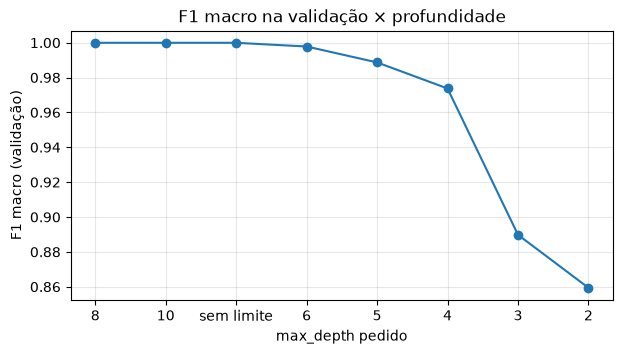

In [8]:
curva = (grade[(grade.criterio == "gini") & (grade.min_samples_leaf == 1)]
         .assign(profundidade=lambda d: d.max_depth.apply(lambda v: "sem limite" if pd.isna(v) else int(v)))
         [["profundidade", "f1_macro_val", "folhas", "prof_real"]])
display(curva)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(curva["profundidade"].astype(str), curva["f1_macro_val"], marker="o")
ax.set_xlabel("max_depth pedido")
ax.set_ylabel("F1 macro (validação)")
ax.set_title("F1 macro na validação × profundidade")
ax.grid(alpha=.3)
plt.show()

## 8. Treinar a árvore oficial (fit só no treino)

Usa a melhor combinação da grade. A árvore é salva em `saida_tarefa3/arvore_oficial.joblib`.

In [9]:
b = grade.iloc[0]
depth = None if pd.isna(b.max_depth) else int(b.max_depth)

modelo = DecisionTreeClassifier(criterion=b.criterio, max_depth=depth,
                                min_samples_leaf=int(b.min_samples_leaf), random_state=SEED)
modelo.fit(X_de(tr, FEATURES), tr[COL_CLASSE])           # fit SÓ no treino
joblib.dump(modelo, SAIDA / "arvore_oficial.joblib")

print(f"Critério ............ {b.criterio}")
print(f"max_depth pedido .... {depth}")
print(f"min_samples_leaf .... {int(b.min_samples_leaf)}")
print(f"Profundidade obtida . {modelo.get_depth()}")
print(f"Folhas .............. {modelo.get_n_leaves()}")
print(f"Semente ............. {SEED}")
print(f"F1 macro validação .. {b.f1_macro_val:.4f}")

Critério ............ gini
max_depth pedido .... 8
min_samples_leaf .... 1
Profundidade obtida . 8
Folhas .............. 19
Semente ............. 42
F1 macro validação .. 0.9999


## 9. A árvore e as primeiras divisões

Texto completo em `saida_tarefa3/arvore_oficial.txt` e figura em `arvore_oficial.png` (primeiros 4 níveis).

In [10]:
txt = export_text(modelo, feature_names=FEATURES)
(SAIDA / "arvore_oficial.txt").write_text(txt, encoding="utf-8")
print(txt)

|--- z_robusto <= 3.50
|   |--- n5_risco <= 1.50
|   |   |--- perda_pct <= 16.67
|   |   |   |--- n5_aumento80 <= 1.50
|   |   |   |   |--- n5_timeout <= 2.50
|   |   |   |   |   |--- class: OK
|   |   |   |   |--- n5_timeout >  2.50
|   |   |   |   |   |--- class: FALHA
|   |   |   |--- n5_aumento80 >  1.50
|   |   |   |   |--- class: FALHA
|   |   |--- perda_pct >  16.67
|   |   |   |--- class: FALHA
|   |--- n5_risco >  1.50
|   |   |--- z_robusto <= 2.00
|   |   |   |--- jitter_relativo <= 3.00
|   |   |   |   |--- n5_aumento80 <= 1.50
|   |   |   |   |   |--- aumento_pct <= 29.81
|   |   |   |   |   |   |--- perda_pct <= 16.67
|   |   |   |   |   |   |   |--- class: OK
|   |   |   |   |   |   |--- perda_pct >  16.67
|   |   |   |   |   |   |   |--- class: FALHA
|   |   |   |   |   |--- aumento_pct >  29.81
|   |   |   |   |   |   |--- aumento_pct <= 84.17
|   |   |   |   |   |   |   |--- perda_pct <= 16.67
|   |   |   |   |   |   |   |   |--- class: RISCO
|   |   |   |   |   |   |

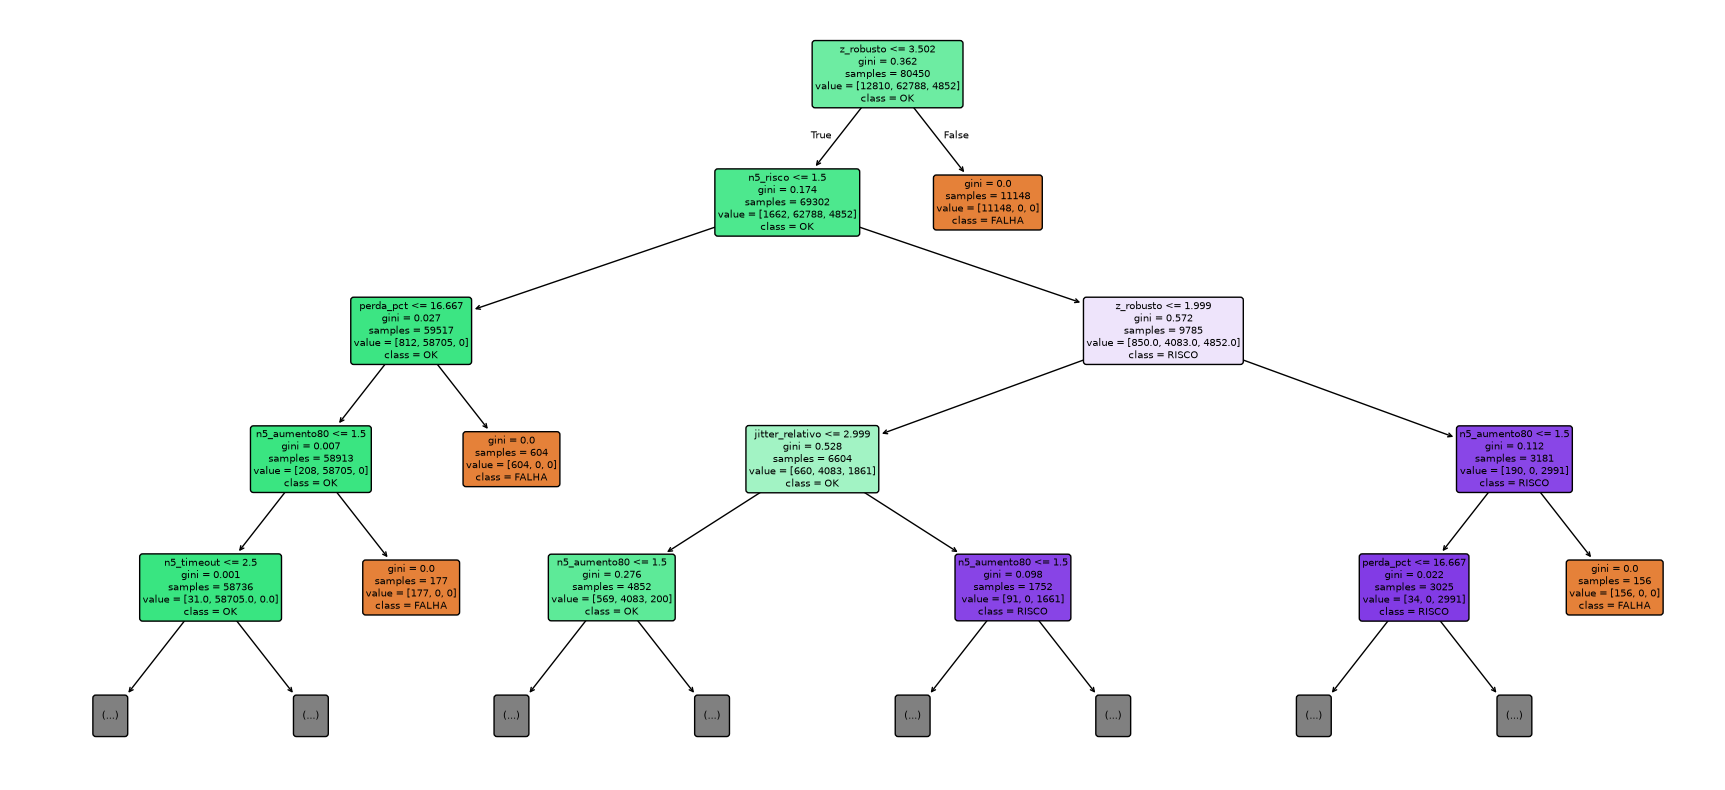

In [11]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(modelo, feature_names=FEATURES, class_names=list(modelo.classes_),
          filled=True, rounded=True, fontsize=7, ax=ax, max_depth=4)
fig.savefig(SAIDA / "arvore_oficial.png", dpi=130, bbox_inches="tight")
plt.show()

### Importância das colunas

In [12]:
imp_of = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values(ascending=False).round(4)
display(imp_of.to_frame("importancia"))

,importancia
z_robusto,0.6469
n5_risco,0.1660
jitter_relativo,0.0679
n5_aumento80,0.0557
perda_pct,0.0482
aumento_pct,0.0129
n5_timeout,0.0025
timeout_atual,0.0000


## 10. Regras lidas da árvore

Cada folha vira uma regra "se métrica ≤ limiar e ... então classe", **copiada da árvore** (não inventada). Abaixo, todas as folhas ordenadas por tamanho e, depois, a maior folha de cada classe para uso no diário.

In [13]:
regras = regras_da_arvore(modelo, FEATURES)
(SAIDA / "regras_arvore.txt").write_text("\n".join(texto_regra(r) for r in regras), encoding="utf-8")

print(f"Total de folhas: {len(regras)}\n")
for r in regras:
    print(texto_regra(r))

Total de folhas: 19

se z_robusto <= 3.502 e n5_risco <= 1.500 e perda_pct <= 16.667 e n5_aumento80 <= 1.500 e n5_timeout <= 2.500 então OK  (n=58705, pureza=100%)
se z_robusto > 3.502 então FALHA  (n=11148, pureza=100%)
se z_robusto <= 3.502 e n5_risco > 1.500 e z_robusto <= 1.999 e jitter_relativo <= 2.999 e n5_aumento80 <= 1.500 e aumento_pct <= 29.806 e perda_pct <= 16.667 então OK  (n=4078, pureza=100%)
se z_robusto <= 3.502 e n5_risco > 1.500 e z_robusto > 1.999 e n5_aumento80 <= 1.500 e perda_pct <= 16.667 e n5_timeout <= 2.500 então RISCO  (n=2991, pureza=100%)
se z_robusto <= 3.502 e n5_risco > 1.500 e z_robusto <= 1.999 e jitter_relativo > 2.999 e n5_aumento80 <= 1.500 e perda_pct <= 16.667 e n5_timeout <= 2.500 então RISCO  (n=1661, pureza=100%)
se z_robusto <= 3.502 e n5_risco <= 1.500 e perda_pct > 16.667 então FALHA  (n=604, pureza=100%)
se z_robusto <= 3.502 e n5_risco > 1.500 e z_robusto <= 1.999 e jitter_relativo <= 2.999 e n5_aumento80 > 1.500 então FALHA  (n=496, pur

In [14]:
# As 3 regras de destaque: maior folha de cada classe presente (cobre OK, RISCO e FALHA)
destaque = []
for c in CLASSES:
    cand = [r for r in regras if r[1] == c]
    if cand:
        destaque.append(cand[0])

for i, r in enumerate(destaque, 1):
    print(f"{i}. {texto_regra(r)}\n")

1. se z_robusto <= 3.502 e n5_risco <= 1.500 e perda_pct <= 16.667 e n5_aumento80 <= 1.500 e n5_timeout <= 2.500 então OK  (n=58705, pureza=100%)

2. se z_robusto <= 3.502 e n5_risco > 1.500 e z_robusto > 1.999 e n5_aumento80 <= 1.500 e perda_pct <= 16.667 e n5_timeout <= 2.500 então RISCO  (n=2991, pureza=100%)

3. se z_robusto > 3.502 então FALHA  (n=11148, pureza=100%)



### Leitura em português

Preencham com as regras acima. Modelo de redação (confirmem com os números reais da execução):

- **OK:** sem pico forte, sem perdas, sem timeouts em sequência e com no máximo uma medição suspeita nas últimas cinco.
- **RISCO:** desvio moderado em relação ao baseline do fluxo e pelo menos duas medições suspeitas nas últimas cinco.
- **FALHA:** desvio robusto acima do limiar de falha, ou perda/timeout em sequência.

## 11. Leitura do erro (validação)

O teste permanece fechado. A **acurácia sozinha não decide**: com maioria OK ela fica alta mesmo errando FALHA. Os critérios são o **F1 macro** e o **recall de FALHA**.

In [15]:
yv = va[COL_CLASSE]
pv = modelo.predict(X_de(va, FEATURES))

cm = pd.DataFrame(confusion_matrix(yv, pv, labels=CLASSES),
                  index=[f"real_{c}" for c in CLASSES], columns=[f"prev_{c}" for c in CLASSES])
cm.to_csv(SAIDA / "matriz_validacao.csv")
print("Matriz 3×3 (validação) — linhas = real, colunas = previsto")
display(cm)

rel = pd.DataFrame(classification_report(yv, pv, labels=CLASSES, output_dict=True,
                                         zero_division=0)).T.round(4)
rel.to_csv(SAIDA / "metricas_validacao.csv")
display(rel)

f1_macro = f1m(yv, pv)
acc = accuracy_score(yv, pv)
print(f"F1 macro (validação): {f1_macro:.4f}")
print(f"Acurácia: {acc:.4f}  (não decide: maioria OK = {(yv == 'OK').mean():.0%})")
print(f"Recall de FALHA: {rel.loc['FALHA', 'recall']:.4f}")

Matriz 3×3 (validação) — linhas = real, colunas = previsto


,prev_OK,prev_RISCO,prev_FALHA
real_OK,24738,0,0
real_RISCO,0,2498,0
real_FALHA,2,0,4944


,precision,recall,f1-score,support
OK,0.9999,1.0000,1.0000,24738.0000
RISCO,1.0000,1.0000,1.0000,2498.0000
FALHA,1.0000,0.9996,0.9998,4946.0000
accuracy,0.9999,0.9999,0.9999,0.9999
macro avg,1.0000,0.9999,0.9999,32182.0000
weighted avg,0.9999,0.9999,0.9999,32182.0000


F1 macro (validação): 0.9999
Acurácia: 0.9999  (não decide: maioria OK = 77%)
Recall de FALHA: 0.9996


### Erros concretos

Procuramos (a) um **caminho longo estável** (real OK) que caiu em FALHA e (b) uma **FALHA** que a árvore classificou como OK. Para separar curto de longo usamos a mediana do baseline do fluxo: acima da mediana das fichas = longo. É só descrição, **não entra em nenhuma regra**.

In [16]:
va = va.assign(pred=pv)
ficha = pd.read_csv(BASELINE)[[COL_FLUXO, COL_MEDIANA]]
va = va.merge(ficha, on=COL_FLUXO, how="left")
corte = ficha[COL_MEDIANA].median()
va["caminho"] = np.where(va[COL_MEDIANA] >= corte, "longo", "curto")
print(f"Corte curto/longo (mediana das fichas): {corte:.2f} ms")

cols_show = [COL_FLUXO, COL_TS, "caminho"] + FEATURES + [COL_CLASSE, "pred"]
e1 = va[(va[COL_CLASSE] == "OK") & (va.pred == "FALHA") & (va.caminho != "curto")]
e2 = va[(va[COL_CLASSE] == "FALHA") & (va.pred == "OK")]
erros = pd.concat([e1.head(5).assign(tipo="longo_estavel_OK->FALHA"),
                   e2.head(5).assign(tipo="FALHA->OK")])

print(f"\nlongo estável OK→FALHA: {len(e1)} | FALHA→OK: {len(e2)}")
if len(erros):
    erros[["tipo"] + cols_show].to_csv(SAIDA / "erros_concretos.csv", index=False)
    display(erros[["tipo"] + cols_show])
else:
    print("Nenhum caso de caminho longo estável em FALHA nem de FALHA curta em OK "
          "apareceu na validação.")

Corte curto/longo (mediana das fichas): 83.09 ms

longo estável OK→FALHA: 0 | FALHA→OK: 2


,tipo,fluxo_id,timestamp,caminho,z_robusto,aumento_pct,jitter_relativo,perda_pct,timeout_atual,n5_timeout,n5_aumento80,n5_risco,classe,pred
2686,FALHA->OK,1003574|143.255.248.149,2026-09-17 03:38:48+00:00,longo,3.500159,3.030180,0.719405,0.0,0,0,0,0,FALHA,OK
27518,FALHA->OK,7101|87.238.48.84,2026-09-17 16:33:28+00:00,curto,3.501371,2.160321,4.886717,0.0,0,0,0,1,FALHA,OK


## 12. Árvore de contraste (não é o modelo)

Treinada no **mesmo treino** e com os **mesmos hiperparâmetros**, acrescentando às 8 métricas o RTT absoluto (`rtt_ms`, reconstruído como mediana × (1 + `aumento_pct`/100)) e a `mediana` do baseline (indica a distância do caminho). Se o dataset tiver `rota_id`, ela entra codificada.

**Esta árvore fica fora da entrega final.**

In [17]:
contraste_cols = list(FEATURES)
trc = tr.copy()
if COL_MEDIANA not in trc.columns:
    trc = trc.merge(ficha, on=COL_FLUXO, how="left")
extras = [c for c in (COL_RTT, COL_MEDIANA) if c in trc.columns]
contraste_cols += extras
if COL_ROTA in trc.columns:
    trc["rota_cod"] = trc[COL_ROTA].astype("category").cat.codes
    contraste_cols.append("rota_cod")

mc = DecisionTreeClassifier(criterion=b.criterio, max_depth=depth,
                            min_samples_leaf=int(b.min_samples_leaf), random_state=SEED)
mc.fit(X_de(trc, contraste_cols), trc[COL_CLASSE])

raiz = contraste_cols[mc.tree_.feature[0]]
lim = mc.tree_.threshold[0]
imp = pd.Series(mc.feature_importances_, index=contraste_cols).sort_values(ascending=False).round(4)
(SAIDA / "arvore_contraste.txt").write_text(export_text(mc, feature_names=contraste_cols), encoding="utf-8")

print("Colunas do contraste:", contraste_cols)
print(f"\nRaiz da árvore de contraste: {raiz} <= {lim:.3f}")
display(imp.head(8).to_frame("importancia"))

Colunas do contraste: ['z_robusto', 'aumento_pct', 'jitter_relativo', 'perda_pct', 'timeout_atual', 'n5_timeout', 'n5_aumento80', 'n5_risco', 'rtt_ms', 'mediana']

Raiz da árvore de contraste: z_robusto <= 3.502


,importancia
z_robusto,0.6469
n5_risco,0.1660
jitter_relativo,0.0679
n5_aumento80,0.0557
perda_pct,0.0482
aumento_pct,0.0129
n5_timeout,0.0025
timeout_atual,0.0000


### Contraste auxiliar: só grandezas absolutas

Se a árvore de contraste ainda usar as métricas relativas na raiz (porque o rótulo é função delas), o atalho da distância não aparece. Para mostrá-lo em **estado puro**, treinamos outra árvore que vê **apenas** `rtt_ms` e `mediana`.

In [18]:
abs_cols = [c for c in (COL_RTT, COL_MEDIANA) if c in trc.columns]
ma = DecisionTreeClassifier(criterion=b.criterio, max_depth=depth,
                            min_samples_leaf=int(b.min_samples_leaf), random_state=SEED)
ma.fit(X_de(trc, abs_cols), trc[COL_CLASSE])

vac = va.copy()
if COL_RTT not in vac.columns:
    vac[COL_RTT] = np.nan
pa = ma.predict(X_de(vac, abs_cols))
recall_falha_abs = ((pa == "FALHA") & (yv.values == "FALHA")).sum() / max((yv == "FALHA").sum(), 1)

(SAIDA / "arvore_contraste_so_absoluto.txt").write_text(
    export_text(ma, feature_names=abs_cols), encoding="utf-8")

print(f"Colunas: {abs_cols}")
print(f"Raiz: {abs_cols[ma.tree_.feature[0]]} <= {ma.tree_.threshold[0]:.3f}")
print(f"F1 macro validação (só absoluto): {f1m(yv, pa):.4f}  vs  oficial: {f1_macro:.4f}")
print(f"Recall de FALHA (só absoluto): {recall_falha_abs:.4f}")
print()
print(export_text(ma, feature_names=abs_cols, max_depth=4))

Colunas: ['rtt_ms', 'mediana']
Raiz: rtt_ms <= -499.465
F1 macro validação (só absoluto): 0.7155  vs  oficial: 0.9999
Recall de FALHA (só absoluto): 0.7673

|--- rtt_ms <= -499.46
|   |--- class: FALHA
|--- rtt_ms >  -499.46
|   |--- mediana <= 40.70
|   |   |--- rtt_ms <= 39.03
|   |   |   |--- rtt_ms <= 27.94
|   |   |   |   |--- mediana <= 0.86
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- mediana >  0.86
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- rtt_ms >  27.94
|   |   |   |   |--- mediana <= 29.03
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- mediana >  29.03
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |--- rtt_ms >  39.03
|   |   |   |--- rtt_ms <= 40.25
|   |   |   |   |--- mediana <= 29.15
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- mediana >  29.15
|   |   |   |   |   |--- class: FALHA
|   |   |   |--- rtt_ms >  40.25
|   |   |   |   |--- rtt_ms <=

### Frase do que a árvore de contraste aprendeu

Complete com os números da execução acima. Modelo:

> *Sem as métricas relativas, a árvore só consegue separar os fluxos pela distância (mediana do caminho e cortes fixos de milissegundos) e fica bem pior (F1 macro X contra Y); por isso o modelo oficial usa só métricas relativas e as árvores de contraste são descartadas.*

## 13. Teste (fechado)

O teste só é aberto na Tarefa 5. Se alguém do grupo já mediu o teste, **registre aqui e não escolha profundidade de novo olhando esse número**.

In [19]:
if MEDIR_TESTE:
    pt = modelo.predict(X_de(te, FEATURES))
    print(f"F1 macro no teste (apenas registro, não usado p/ escolher nada): {f1m(te[COL_CLASSE], pt):.4f}")
else:
    print("Teste não medido nesta tarefa (fica fechado até a Tarefa 5).")

Teste não medido nesta tarefa (fica fechado até a Tarefa 5).


## 14. Registrar a configuração do modelo

Fica salvo o que a Tarefa 4 precisa para mexer nesta árvore (e não no rótulo).

In [20]:
config_modelo = dict(criterio=b.criterio, max_depth=depth, min_samples_leaf=int(b.min_samples_leaf),
                     seed=SEED, f1_macro_val=float(f1_macro), raiz_contraste=raiz,
                     features=FEATURES)
with open(SAIDA / "config_modelo.json", "w", encoding="utf-8") as f:
    json.dump(config_modelo, f, indent=2, ensure_ascii=False)

arquivos = sorted(p.name for p in SAIDA.iterdir())
print("Arquivos gerados em", SAIDA.resolve())
for a in arquivos:
    print(" -", a)

Arquivos gerados em /home/thxin/Documents/Faculdade/Estrutura-De-Dados-II/icmpmaster/documentos/notebooks/Arvore/saida_tarefa3
 - arvore_contraste.txt
 - arvore_contraste_so_absoluto.txt
 - arvore_oficial.joblib
 - arvore_oficial.png
 - arvore_oficial.txt
 - config_modelo.json
 - erros_concretos.csv
 - grade_validacao.csv
 - matriz_validacao.csv
 - metricas_validacao.csv
 - regras_arvore.txt


## 15. Achado: possível vazamento de rótulo

Se o F1 macro da árvore oficial ficar praticamente em 1,0, confiram: as colunas de entrada são as **mesmas grandezas** que a tabela de rotulagem da Tarefa 2 usa (`perda_pct`, `n5_timeout`, `z_robusto`, `n5_aumento80`, `n5_risco`). Se os limiares aprendidos coincidirem com os da tabela, a árvore apenas **redescobriu a regra do rótulo**. Isso mostra coerência com o rótulo, **não** que generaliza para degradação real.

É o principal ponto a atacar na Tarefa 4 (por exemplo, prever o estado 12 minutos à frente, o horizonte do preditor definido na Tarefa 1).

## 16. Contribuições individuais

| Integrante | O que fiz nesta tarefa | Dificuldades | O que pretendo manter/ajustar |
|---|---|---|---|
| Eduardo Quintino Filho | | | |
| Felipe Veiga da Silva | | | |
| Henrique de Aguiar Fernandes (SM) | | | |
| Niccolas Lupetti dos Santos | | | |
| Tharik Lima da Silva | | | |

**Board atualizado:** (colar o link do board)

**Evidências aceitas:** histórico de edição, commit/PR no GitHub, código produzido, registro de tarefa no board, registro de testes ou outro material que identifique o aluno e a atividade.

## 17. Checklist da equipe

- [ ] Treino, validação e teste são os da Tarefa 2 (coluna `particao`, sem alteração)
- [ ] A ficha de baseline não foi recalculada com o Período B
- [ ] Lista de colunas do treino colada no diário; a classe é o alvo, não feature
- [ ] Uma árvore CART, critério declarado (gini ou entropy)
- [ ] `max_depth` e `min_samples_leaf` escolhidos olhando só a validação
- [ ] Semente registrada (`random_state = 42`) e `fit` só no treino
- [ ] Profundidade real, folhas e primeiras divisões descritas
- [ ] Pelo menos três regras copiadas da árvore
- [ ] Matriz 3×3, precisão/recall/F1 por classe e F1 macro (validação)
- [ ] Dois erros concretos (ou declaração de que não apareceram)
- [ ] Árvore de contraste treinada, raiz registrada e declarada fora da entrega final
- [ ] Teste fechado (ou registrado sem reescolher profundidade)
- [ ] Board atualizado e diário de todos preenchido